In [1]:
import numpy as np
import array as arr
import awkward as ak
import os
import matplotlib.pyplot as plt
#from analysis import Analysis
import logging
import pickle
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
os.environ['MEDULLA_PLOT_DIR'] =  '/nashome/m/micarrig/icarus/nuESpine/medulla/spineplot/'
sys.path.append('/nashome/m/micarrig/icarus/nuESpine/medulla/spineplot/')
from efficiency import SpineEfficiency
from analysis import Analysis
from style import make_styled_plot, apply_style_to_plot, stamp
import uproot
plt.style.use('/nashome/m/micarrig/icarus/nuESpine/medulla/spineplot/styles/nue2024.mplstyle')

In [2]:
def extract_category(fig, idx):
    """Extract bin heights and edges for a named category from a SpineSpectra1D stacked histogram."""
    ax = fig.axes[0]
    container = ax.containers[idx]
    patches   = container.patches
    heights   = np.array([p.get_height() for p in patches])
    x_left    = np.array([p.get_x()      for p in patches])
    widths    = np.array([p.get_width()   for p in patches])
    bin_edges = np.append(x_left, x_left[-1] + widths[-1])
    return heights, bin_edges
    raise ValueError(f"Category '{label}' not found in figure. Available: {[c.get_label() for c in ax.containers]}")

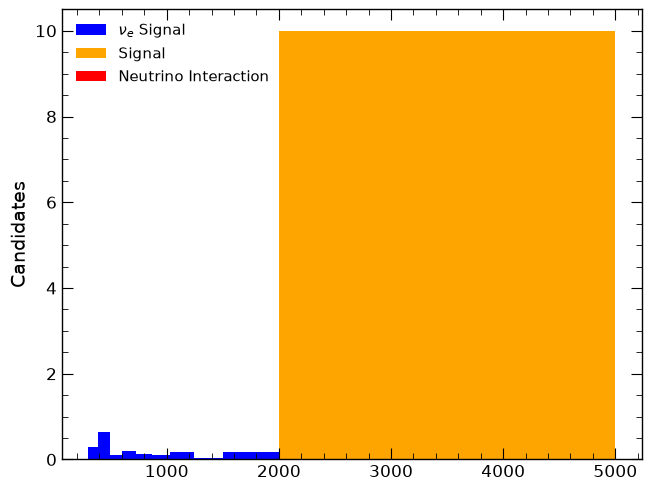

In [3]:
with open('/nashome/m/micarrig/icarus/nuESpine/plots_sept15/all_events/plot_reco_leading_electron_energy.pkl', 'rb') as f:
    fig = pickle.load(f)
plt.close(fig)
heights_all, bin_edges_all = extract_category(fig, 2)

with open('/nashome/m/micarrig/icarus/nuESpine/plots_sept15/true_signal/plot_reco_leading_electron_energy.pkl', 'rb') as f:
    fig = pickle.load(f)
plt.close(fig)
heights_signal, bin_edges_signal = extract_category(fig, 2)

with open('/nashome/m/micarrig/icarus/nuESpine/plots_sept15/neutrino_interaction/plot_reco_leading_electron_energy.pkl', 'rb') as f:
    fig = pickle.load(f)
plt.close(fig)
heights_inter, bin_edges_inter = extract_category(fig, 2)

fig2, ax2 = plt.subplots()
ax2.stairs(heights_all, bin_edges_all, fill=True, label=r'$\nu_{e}$ Signal', color='blue')
ax2.hist(heights_signal, bin_edges_signal, fill=True, label='Signal', color='orange')
ax2.hist(heights_inter, bin_edges_inter, fill=True, label='Neutrino Interaction', color='red')
ax2.set_xlabel(fig.axes[0].get_xlabel())
ax2.set_ylabel(fig.axes[0].get_ylabel())
ax2.legend()
plt.show()

In [4]:
fin = uproot.open('/exp/icarus/data/users/micarrig/merged_v30.root')

all_energy = fin['events/NuMIFull/all/reco_leading_electron_energy'].array(library='np')
all_cat = fin['events/NuMIFull/all/true_category'].array(library='np')
signal_energy = fin['events/NuMIFull/true_signal/reco_leading_electron_energy'].array(library='np')
signal_cat = fin['events/NuMIFull/true_signal/true_category'].array(library='np')
selected_energy = fin['events/NuMIFull/selected/reco_leading_electron_energy'].array(library='np')
selected_cat = fin['events/NuMIFull/selected/true_category'].array(library='np')

/tmp/ipykernel_4982/912554999.py:16: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  fig.subplots_adjust(hspace=0.05)


[150.0, 345.0, 440.0, 545.0, 665.0, 800.0, 950.0, 1135.0, 1370.0, 1750.0, 3500.0]


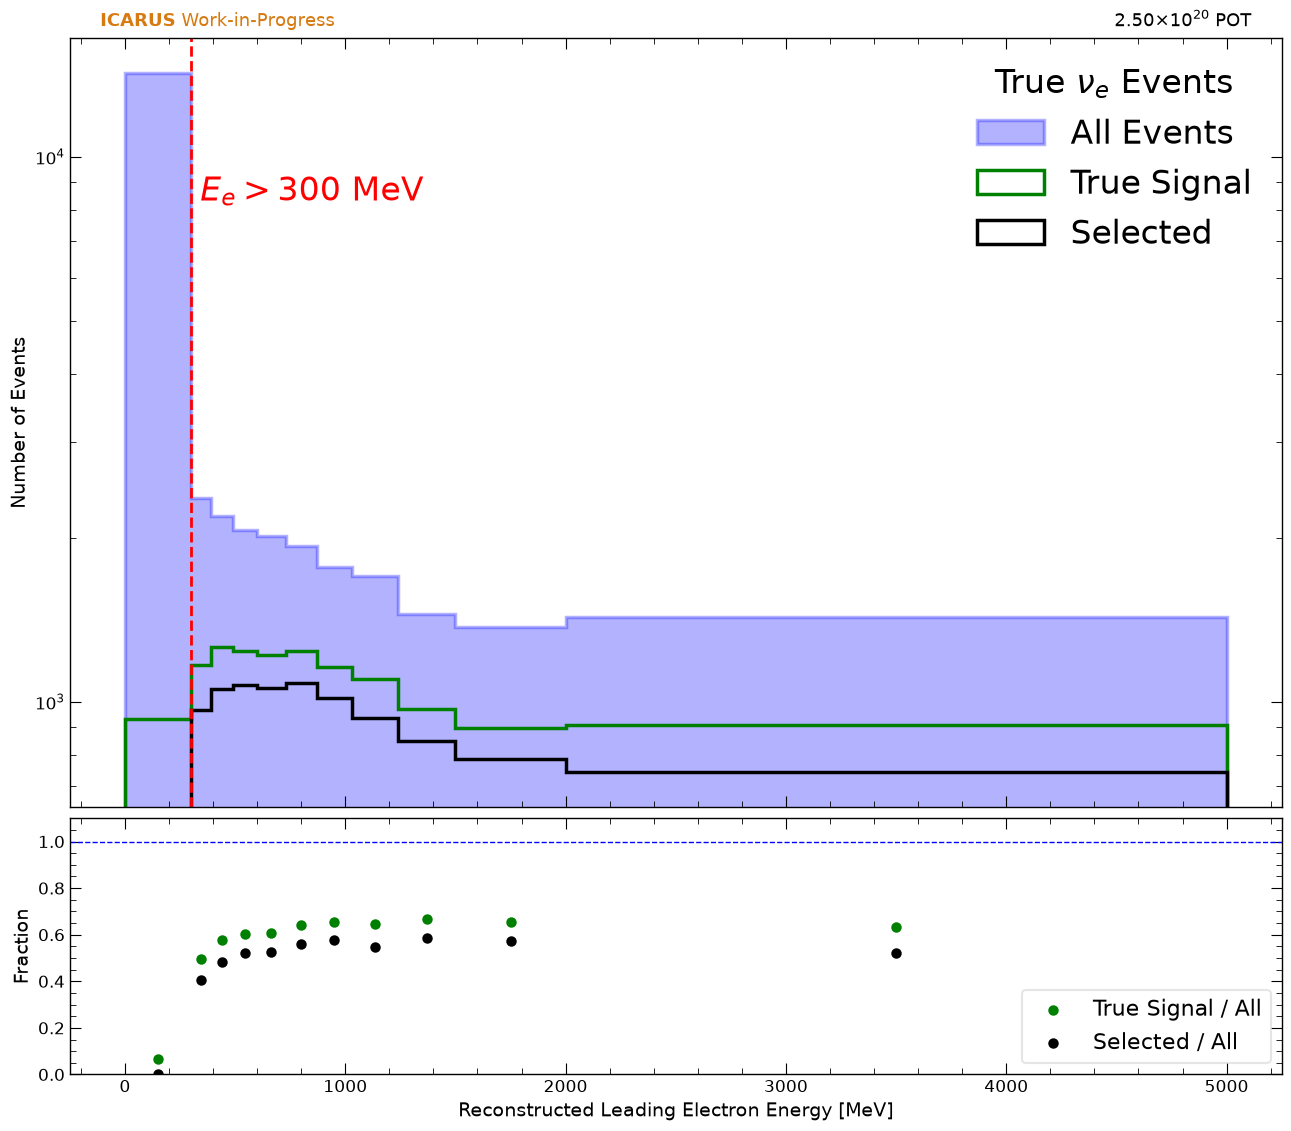

In [5]:
bins = [0, 300, 390, 490, 600, 730, 870, 1030, 1240, 1500, 2000, 5000]

all_hist,      _ = np.histogram(all_energy[(all_cat==0) | (all_cat==1)],           bins=bins)
signal_hist,   _ = np.histogram(signal_energy[signal_cat==0],     bins=bins)
selected_hist, _ = np.histogram(selected_energy[selected_cat==0], bins=bins)

with np.errstate(divide='ignore', invalid='ignore'):
    signal_ratio   = np.where(all_hist > 0, signal_hist   / all_hist, np.nan)
    selected_ratio = np.where(all_hist > 0, selected_hist / all_hist, np.nan)

bin_centers = 0.5 * (np.array(bins[:-1]) + np.array(bins[1:]))

fig, (ax, ax_ratio) = plt.subplots(2, 1, figsize=(12.8, 11.2),
                                    gridspec_kw={'height_ratios': [3, 1]},
                                    sharex=True)
fig.subplots_adjust(hspace=0.05)

ax.hist(all_energy[(all_cat==0) | (all_cat==1)],           bins=bins, histtype='stepfilled', label='All Events',      color='blue',  alpha=0.3, edgecolor='blue',  linewidth=2.5)
ax.hist(signal_energy[signal_cat==0],     bins=bins, histtype='step',       label='True Signal',     color='black', edgecolor='green', linewidth=2.5)
ax.hist(selected_energy[selected_cat==0], bins=bins, histtype='step',       label='Selected', color='red',   edgecolor='black',   linewidth=2.5)
ax.legend(title=r'True $\nu_e$ Events', fontsize=24, title_fontsize=24, loc='upper right')
ax.set_yscale('log')
ax.set_ylabel('Number of Events')
ax.axvline(300, color='red', linestyle='--', linewidth=2)
ax.text(0.2, 0.8, r'$E_{e}>300$ MeV', transform=ax.transAxes, fontsize=24, ha='center', va='center', color='red')
stamp(ax, pot=2.5e20, work_in_progress=True)

ratio_bins = [bins[i] + (bins[i+1] - bins[i]) / 2 for i in range(len(bins) - 1)]
print(ratio_bins)

ax_ratio.scatter(ratio_bins, signal_ratio, color='green', label='True Signal / All')
ax_ratio.scatter(ratio_bins, selected_ratio, color='black', label='Selected / All')
ax_ratio.axhline(1, color='blue', linestyle='--', linewidth=1)
ax_ratio.set_ylabel('Fraction')
ax_ratio.set_xlabel('Reconstructed Leading Electron Energy [MeV]')
ax_ratio.set_ylim(0, 1.1)
ax_ratio.legend(fontsize=16, loc='lower right', framealpha=0.5, facecolor='white', frameon=True,)

plt.show()

In [6]:
all_cos = fin['events/NuMIFull/all/reco_ele_beam_open_angle'].array(library='np')
signal_cos = fin['events/NuMIFull/true_signal/reco_ele_beam_open_angle'].array(library='np')
selected_cos = fin['events/NuMIFull/selected/reco_ele_beam_open_angle'].array(library='np')

/tmp/ipykernel_4982/3262977809.py:16: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  fig.subplots_adjust(hspace=0.05)


[-0.7, -0.2, 0.1, 0.275, 0.425, 0.5625, 0.675, 0.7625, 0.825, 0.875, 0.9199999999999999, 0.955, 0.985]


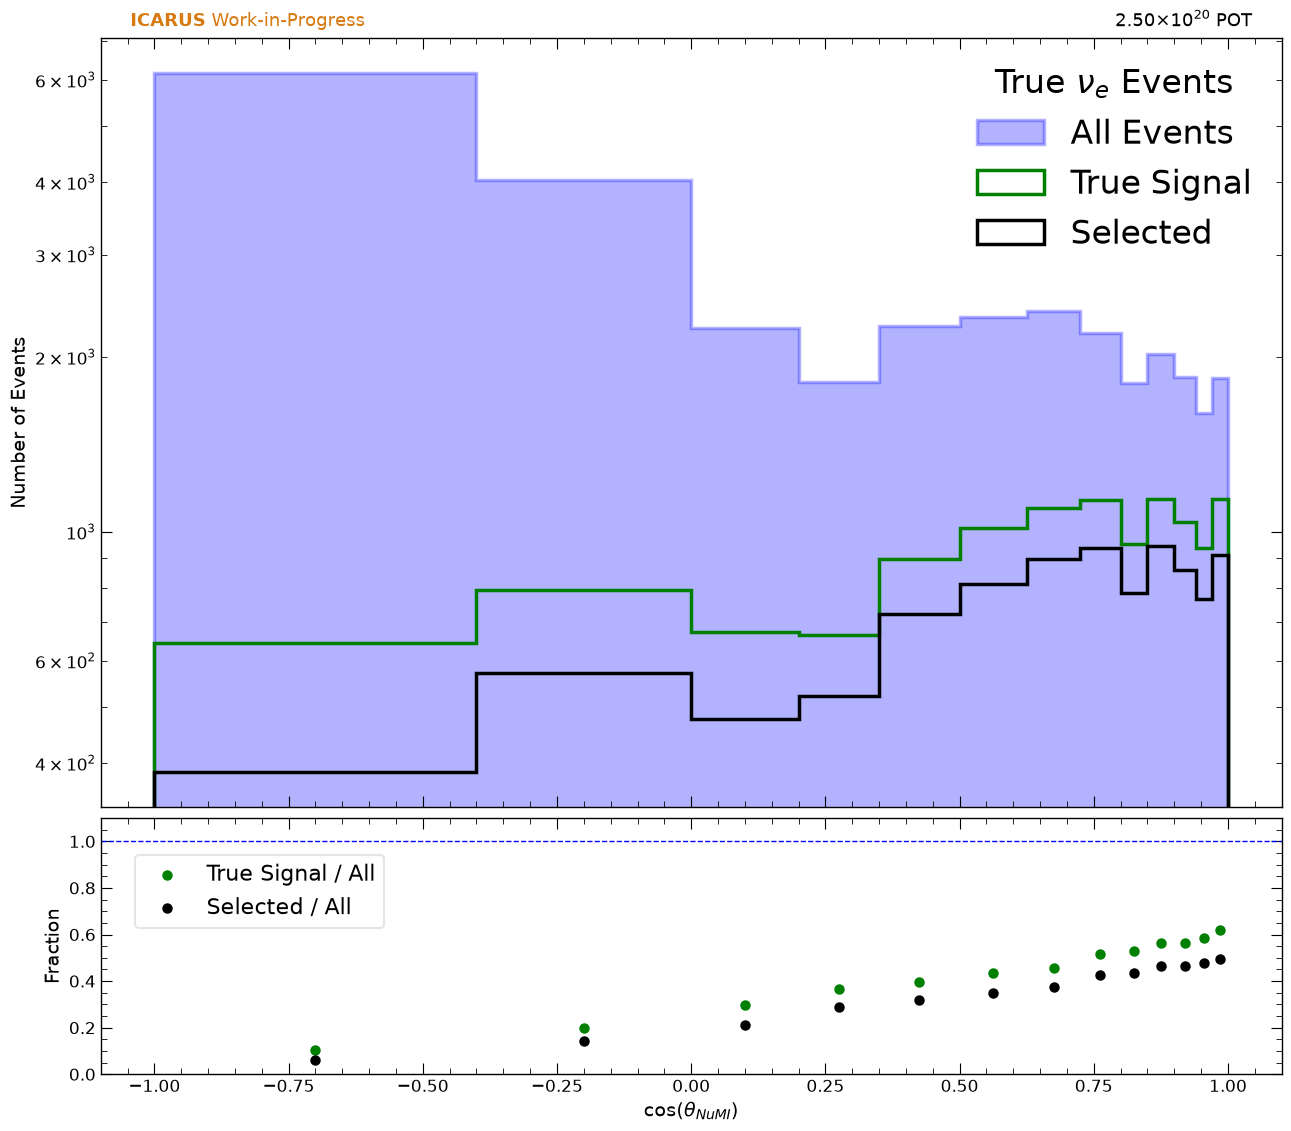

In [7]:
bins = [-1.0, -0.4, 0.0, 0.2, 0.35, 0.5, 0.625, 0.725, 0.8, 0.85, 0.9, 0.94, 0.97, 1.0]

all_hist,      _ = np.histogram(all_cos[(all_cat==0) | (all_cat==1)],           bins=bins)
signal_hist,   _ = np.histogram(signal_cos[signal_cat==0],     bins=bins)
selected_hist, _ = np.histogram(selected_cos[selected_cat==0], bins=bins)

with np.errstate(divide='ignore', invalid='ignore'):
    signal_ratio   = np.where(all_hist > 0, signal_hist   / all_hist, np.nan)
    selected_ratio = np.where(all_hist > 0, selected_hist / all_hist, np.nan)

bin_centers = 0.5 * (np.array(bins[:-1]) + np.array(bins[1:]))

fig, (ax, ax_ratio) = plt.subplots(2, 1, figsize=(12.8, 11.2),
                                    gridspec_kw={'height_ratios': [3, 1]},
                                    sharex=True)
fig.subplots_adjust(hspace=0.05)

ax.hist(all_cos[(all_cat==0) | (all_cat==1)],           bins=bins, histtype='stepfilled', label='All Events',      color='blue',  alpha=0.3, edgecolor='blue',  linewidth=2.5)
ax.hist(signal_cos[signal_cat==0],     bins=bins, histtype='step',       label='True Signal',     color='black', edgecolor='green', linewidth=2.5)
ax.hist(selected_cos[selected_cat==0], bins=bins, histtype='step',       label='Selected', color='red',   edgecolor='black',   linewidth=2.5)
ax.legend(title=r'True $\nu_e$ Events', fontsize=24, title_fontsize=24, loc='upper right')
ax.set_yscale('log')
ax.set_ylabel('Number of Events')
stamp(ax, pot=2.5e20, work_in_progress=True)

ratio_bins = [bins[i] + (bins[i+1] - bins[i]) / 2 for i in range(len(bins) - 1)]
print(ratio_bins)

ax_ratio.scatter(ratio_bins, signal_ratio, color='green', label='True Signal / All')
ax_ratio.scatter(ratio_bins, selected_ratio, color='black', label='Selected / All')
ax_ratio.axhline(1, color='blue', linestyle='--', linewidth=1)
ax_ratio.set_ylabel('Fraction')
ax_ratio.set_xlabel(r'$\cos(\theta_{NuMI})$')
ax_ratio.set_ylim(0, 1.1)
ax_ratio.legend(fontsize=16, loc='upper left', framealpha=0.5, facecolor='white', frameon=True, bbox_to_anchor=(0.02, 0.9))

plt.show()

In [8]:
all_vx = fin['events/NuMIFull/all/reco_leading_electron_start_x'].array(library='np')
signal_vx = fin['events/NuMIFull/true_signal/reco_leading_electron_start_x'].array(library='np')
selected_vx = fin['events/NuMIFull/selected/reco_leading_electron_start_x'].array(library='np')

all_vy = fin['events/NuMIFull/all/reco_leading_electron_start_y'].array(library='np')
signal_vy = fin['events/NuMIFull/true_signal/reco_leading_electron_start_y'].array(library='np')
selected_vy = fin['events/NuMIFull/selected/reco_leading_electron_start_y'].array(library='np')

all_vz = fin['events/NuMIFull/all/reco_leading_electron_start_z'].array(library='np')
signal_vz = fin['events/NuMIFull/true_signal/reco_leading_electron_start_z'].array(library='np')
selected_vz = fin['events/NuMIFull/selected/reco_leading_electron_start_z'].array(library='np')

/tmp/ipykernel_4982/1065063582.py:16: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  fig.subplots_adjust(hspace=0.05)


[np.float64(-545.0), np.float64(-535.0), np.float64(-525.0), np.float64(-515.0), np.float64(-505.0), np.float64(-495.0), np.float64(-485.0), np.float64(-475.0), np.float64(-465.0), np.float64(-455.0), np.float64(-445.0), np.float64(-435.0), np.float64(-425.0), np.float64(-415.0), np.float64(-405.0), np.float64(-395.0), np.float64(-385.0), np.float64(-375.0), np.float64(-365.0), np.float64(-355.0), np.float64(-345.0), np.float64(-335.0), np.float64(-325.0), np.float64(-315.0), np.float64(-305.0), np.float64(-295.0), np.float64(-285.0), np.float64(-275.0), np.float64(-265.0), np.float64(-255.0), np.float64(-245.0), np.float64(-235.0), np.float64(-225.0), np.float64(-215.0), np.float64(-205.0), np.float64(-195.0), np.float64(-185.0), np.float64(-175.0), np.float64(-165.0), np.float64(-155.0), np.float64(-145.0), np.float64(-135.0), np.float64(-125.0), np.float64(-115.0), np.float64(-105.0), np.float64(-95.0), np.float64(-85.0), np.float64(-75.0), np.float64(-65.0), np.float64(-55.0), np.f

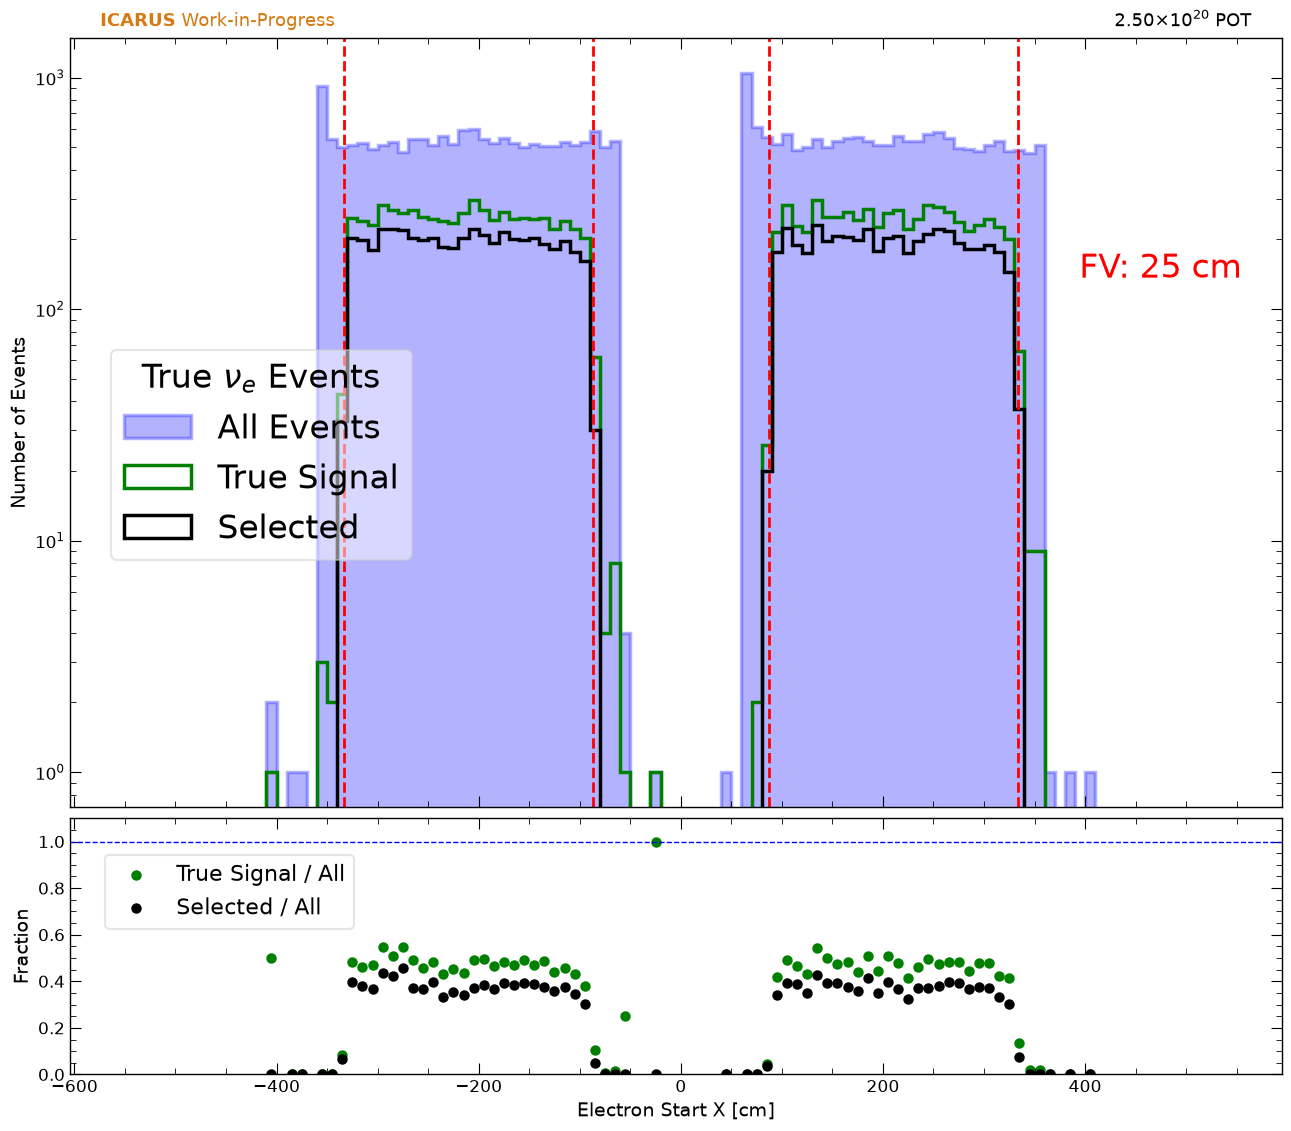

In [36]:
bins = np.arange(-550, 550, 10)

all_hist,      _ = np.histogram(all_vx[(all_cat==0) | (all_cat==1)],           bins=bins)
signal_hist,   _ = np.histogram(signal_vx[signal_cat==0],     bins=bins)
selected_hist, _ = np.histogram(selected_vx[selected_cat==0], bins=bins)

with np.errstate(divide='ignore', invalid='ignore'):
    signal_ratio   = np.where(all_hist > 0, signal_hist   / all_hist, np.nan)
    selected_ratio = np.where(all_hist > 0, selected_hist / all_hist, np.nan)

bin_centers = 0.5 * (np.array(bins[:-1]) + np.array(bins[1:]))

fig, (ax, ax_ratio) = plt.subplots(2, 1, figsize=(12.8, 11.2),
                                    gridspec_kw={'height_ratios': [3, 1]},
                                    sharex=True)
fig.subplots_adjust(hspace=0.05)

ax.hist(all_vx[(all_cat==0) | (all_cat==1)],           bins=bins, histtype='stepfilled', label='All Events',      color='blue',  alpha=0.3, edgecolor='blue',  linewidth=2.5)
ax.hist(signal_vx[signal_cat==0],     bins=bins, histtype='step',       label='True Signal',     color='black', edgecolor='green', linewidth=2.5)
ax.hist(selected_vx[selected_cat==0], bins=bins, histtype='step',       label='Selected', color='red',   edgecolor='black',   linewidth=2.5)
ax.legend(title=r'True $\nu_e$ Events', fontsize=24, title_fontsize=24, loc='lower left', frameon=True, framealpha=0.5, facecolor='white', bbox_to_anchor=(0.02, 0.3))
ax.set_yscale('log')
ax.set_ylabel('Number of Events')

ax.axvline(-358.49+25, color='red', linestyle='--', linewidth=2)
ax.axvline(358.49-25, color='red', linestyle='--', linewidth=2)
ax.axvline(-61.94-25, color='red', linestyle='--', linewidth=2)
ax.axvline(61.94+25, color='red', linestyle='--', linewidth=2)
ax.text(0.9, 0.7, r'FV: 25 cm', transform=ax.transAxes, fontsize=24, ha='center', va='center', color='red')

stamp(ax, pot=2.5e20, work_in_progress=True)

ratio_bins = [bins[i] + (bins[i+1] - bins[i]) / 2 for i in range(len(bins) - 1)]
print(ratio_bins)

ax_ratio.scatter(ratio_bins, signal_ratio, color='green', label='True Signal / All')
ax_ratio.scatter(ratio_bins, selected_ratio, color='black', label='Selected / All')
ax_ratio.axhline(1, color='blue', linestyle='--', linewidth=1)
ax_ratio.set_ylabel('Fraction')
ax_ratio.set_xlabel(r'Electron Start X [cm]')
ax_ratio.set_ylim(0, 1.1)
ax_ratio.legend(fontsize=16, loc='upper left', framealpha=0.5, facecolor='white', frameon=True, bbox_to_anchor=(0.02, 0.9))

plt.show()

/tmp/ipykernel_4982/2095361269.py:16: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  fig.subplots_adjust(hspace=0.05)


[np.float64(-245.0), np.float64(-235.0), np.float64(-225.0), np.float64(-215.0), np.float64(-205.0), np.float64(-195.0), np.float64(-185.0), np.float64(-175.0), np.float64(-165.0), np.float64(-155.0), np.float64(-145.0), np.float64(-135.0), np.float64(-125.0), np.float64(-115.0), np.float64(-105.0), np.float64(-95.0), np.float64(-85.0), np.float64(-75.0), np.float64(-65.0), np.float64(-55.0), np.float64(-45.0), np.float64(-35.0), np.float64(-25.0), np.float64(-15.0), np.float64(-5.0), np.float64(5.0), np.float64(15.0), np.float64(25.0), np.float64(35.0), np.float64(45.0), np.float64(55.0), np.float64(65.0), np.float64(75.0), np.float64(85.0), np.float64(95.0), np.float64(105.0), np.float64(115.0), np.float64(125.0), np.float64(135.0), np.float64(145.0), np.float64(155.0), np.float64(165.0), np.float64(175.0), np.float64(185.0), np.float64(195.0), np.float64(205.0), np.float64(215.0), np.float64(225.0), np.float64(235.0)]


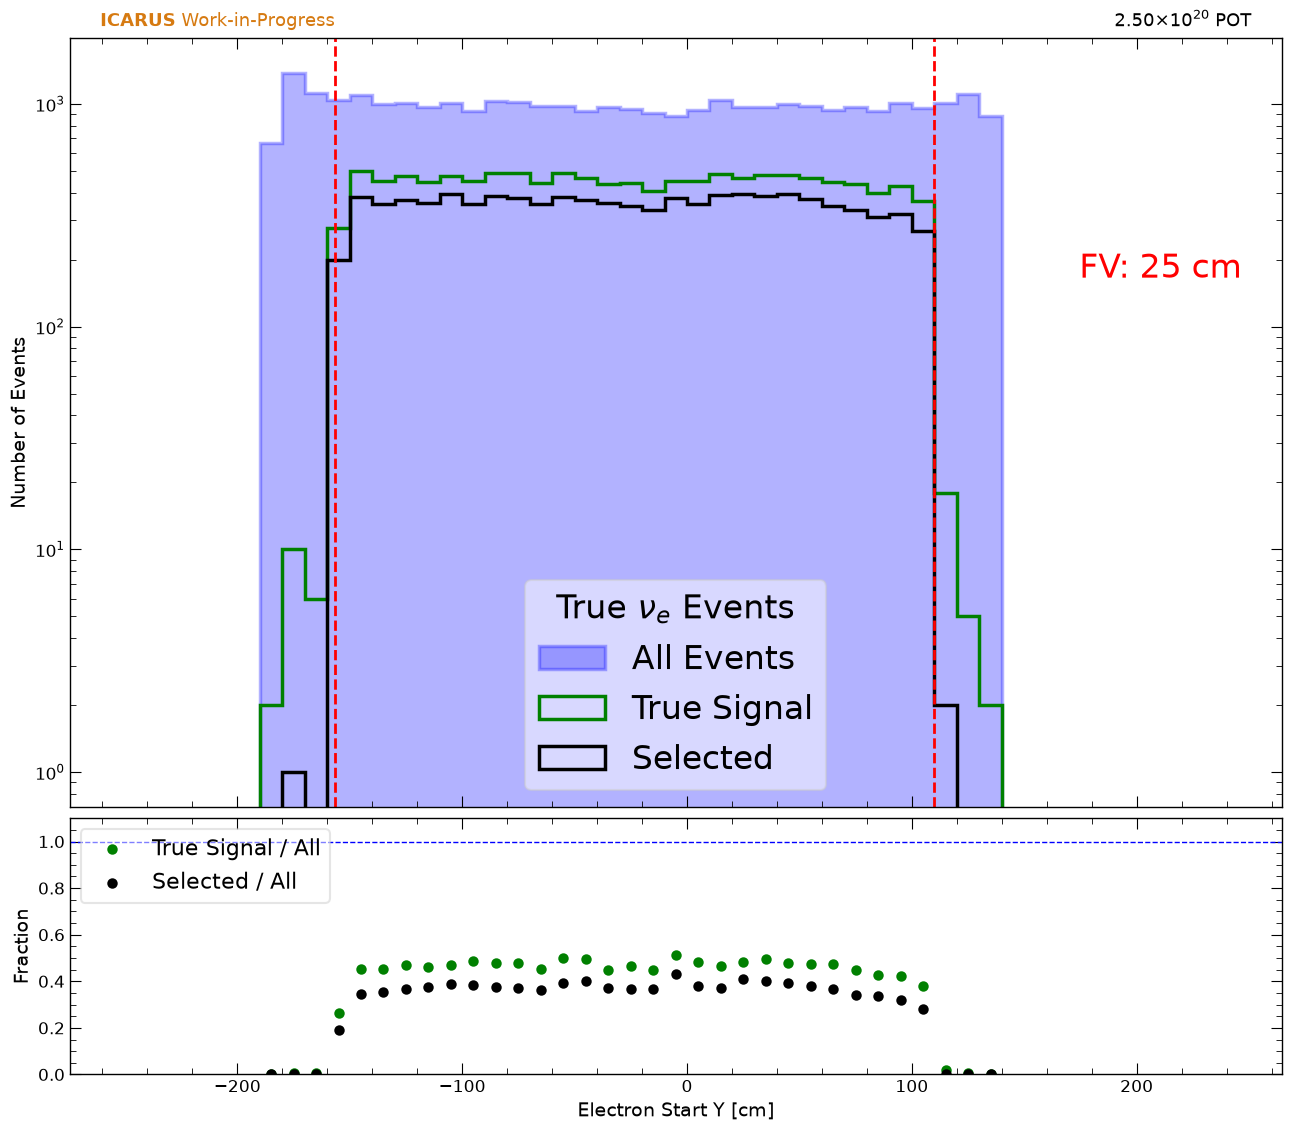

In [38]:
bins = np.arange(-250, 250, 10)

all_hist,      _ = np.histogram(all_vy[(all_cat==0) | (all_cat==1)],           bins=bins)
signal_hist,   _ = np.histogram(signal_vy[signal_cat==0],     bins=bins)
selected_hist, _ = np.histogram(selected_vy[selected_cat==0], bins=bins)

with np.errstate(divide='ignore', invalid='ignore'):
    signal_ratio   = np.where(all_hist > 0, signal_hist   / all_hist, np.nan)
    selected_ratio = np.where(all_hist > 0, selected_hist / all_hist, np.nan)

bin_centers = 0.5 * (np.array(bins[:-1]) + np.array(bins[1:]))

fig, (ax, ax_ratio) = plt.subplots(2, 1, figsize=(12.8, 11.2),
                                    gridspec_kw={'height_ratios': [3, 1]},
                                    sharex=True)
fig.subplots_adjust(hspace=0.05)

ax.hist(all_vy[(all_cat==0) | (all_cat==1)],           bins=bins, histtype='stepfilled', label='All Events',      color='blue',  alpha=0.3, edgecolor='blue',  linewidth=2.5)
ax.hist(signal_vy[signal_cat==0],     bins=bins, histtype='step',       label='True Signal',     color='black', edgecolor='green', linewidth=2.5)
ax.hist(selected_vy[selected_cat==0], bins=bins, histtype='step',       label='Selected', color='red',   edgecolor='black',   linewidth=2.5)
ax.legend(title=r'True $\nu_e$ Events', fontsize=24, title_fontsize=24, loc='best', frameon=True, framealpha=0.5, facecolor='white')
ax.set_yscale('log')
ax.set_ylabel('Number of Events')

ax.axvline(-181.68+25, color='red', linestyle='--', linewidth=2)
ax.axvline(134.96-25, color='red', linestyle='--', linewidth=2)
ax.text(0.9, 0.7, r'FV: 25 cm', transform=ax.transAxes, fontsize=24, ha='center', va='center', color='red')

stamp(ax, pot=2.5e20, work_in_progress=True)

ratio_bins = [bins[i] + (bins[i+1] - bins[i]) / 2 for i in range(len(bins) - 1)]
print(ratio_bins)

ax_ratio.scatter(ratio_bins, signal_ratio, color='green', label='True Signal / All')
ax_ratio.scatter(ratio_bins, selected_ratio, color='black', label='Selected / All')
ax_ratio.axhline(1, color='blue', linestyle='--', linewidth=1)
ax_ratio.set_ylabel('Fraction')
ax_ratio.set_xlabel(r'Electron Start Y [cm]')
ax_ratio.set_ylim(0, 1.1)
ax_ratio.legend(fontsize=16, loc='upper left', framealpha=0.5, facecolor='white', frameon=True,)

plt.show()

/tmp/ipykernel_4982/3120720693.py:16: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  fig.subplots_adjust(hspace=0.05)


[np.float64(-995.0), np.float64(-985.0), np.float64(-975.0), np.float64(-965.0), np.float64(-955.0), np.float64(-945.0), np.float64(-935.0), np.float64(-925.0), np.float64(-915.0), np.float64(-905.0), np.float64(-895.0), np.float64(-885.0), np.float64(-875.0), np.float64(-865.0), np.float64(-855.0), np.float64(-845.0), np.float64(-835.0), np.float64(-825.0), np.float64(-815.0), np.float64(-805.0), np.float64(-795.0), np.float64(-785.0), np.float64(-775.0), np.float64(-765.0), np.float64(-755.0), np.float64(-745.0), np.float64(-735.0), np.float64(-725.0), np.float64(-715.0), np.float64(-705.0), np.float64(-695.0), np.float64(-685.0), np.float64(-675.0), np.float64(-665.0), np.float64(-655.0), np.float64(-645.0), np.float64(-635.0), np.float64(-625.0), np.float64(-615.0), np.float64(-605.0), np.float64(-595.0), np.float64(-585.0), np.float64(-575.0), np.float64(-565.0), np.float64(-555.0), np.float64(-545.0), np.float64(-535.0), np.float64(-525.0), np.float64(-515.0), np.float64(-505.0),

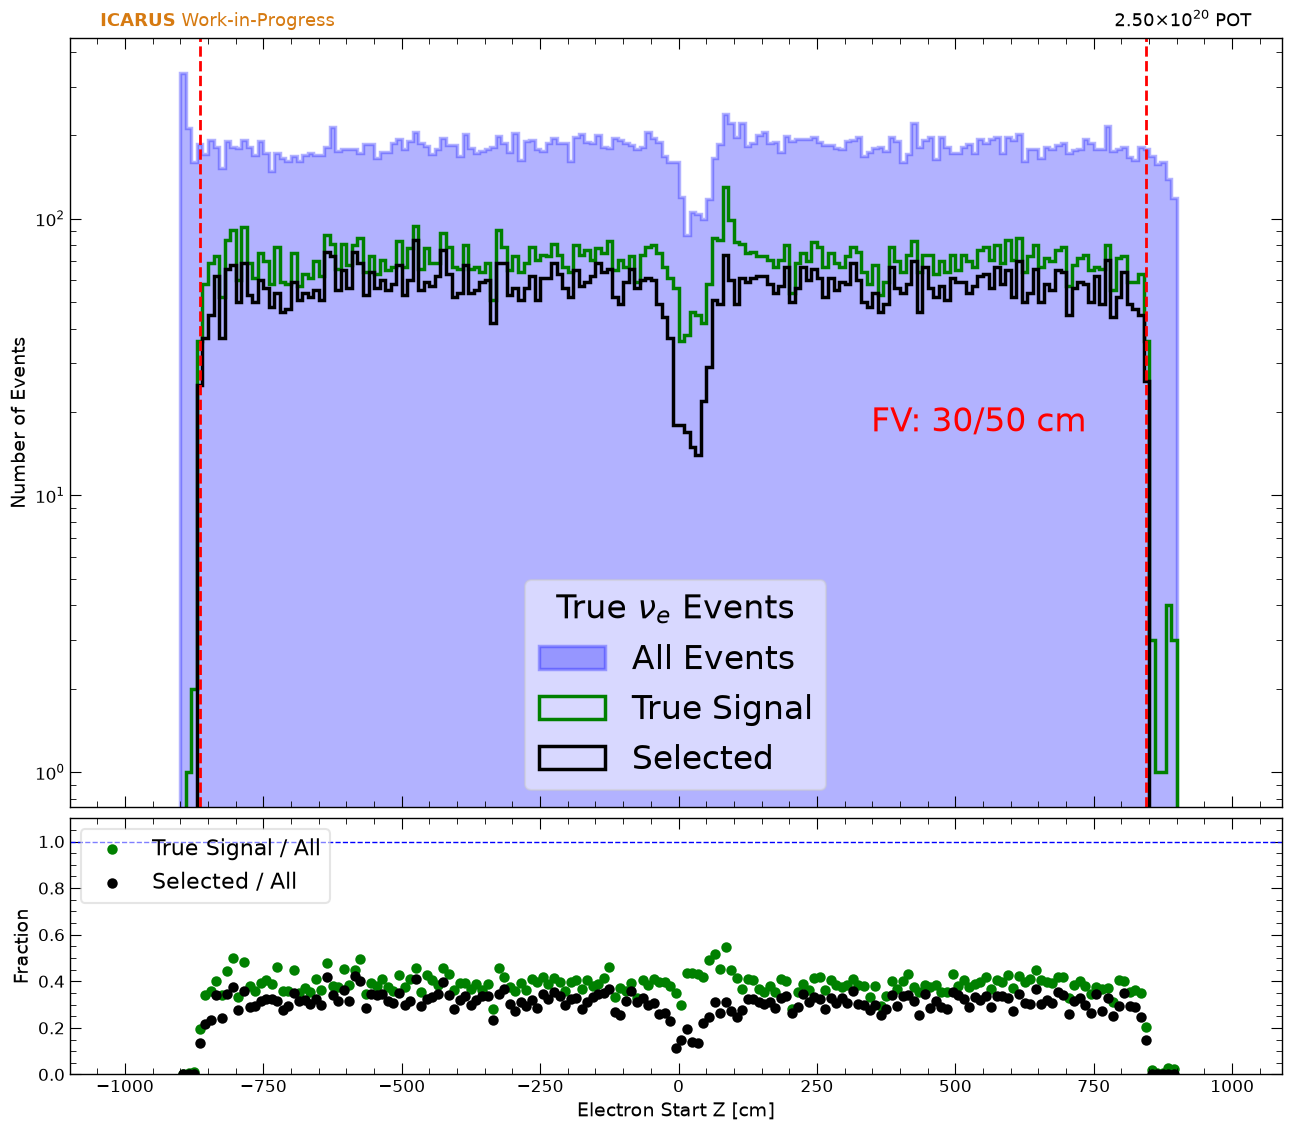

In [37]:
bins = np.arange(-1000, 1000, 10)

all_hist,      _ = np.histogram(all_vz[(all_cat==0) | (all_cat==1)],           bins=bins)
signal_hist,   _ = np.histogram(signal_vz[signal_cat==0],     bins=bins)
selected_hist, _ = np.histogram(selected_vz[selected_cat==0], bins=bins)

with np.errstate(divide='ignore', invalid='ignore'):
    signal_ratio   = np.where(all_hist > 0, signal_hist   / all_hist, np.nan)
    selected_ratio = np.where(all_hist > 0, selected_hist / all_hist, np.nan)

bin_centers = 0.5 * (np.array(bins[:-1]) + np.array(bins[1:]))

fig, (ax, ax_ratio) = plt.subplots(2, 1, figsize=(12.8, 11.2),
                                    gridspec_kw={'height_ratios': [3, 1]},
                                    sharex=True)
fig.subplots_adjust(hspace=0.05)

ax.hist(all_vz[(all_cat==0) | (all_cat==1)],           bins=bins, histtype='stepfilled', label='All Events',      color='blue',  alpha=0.3, edgecolor='blue',  linewidth=2.5)
ax.hist(signal_vz[signal_cat==0],     bins=bins, histtype='step',       label='True Signal',     color='black', edgecolor='green', linewidth=2.5)
ax.hist(selected_vz[selected_cat==0], bins=bins, histtype='step',       label='Selected', color='red',   edgecolor='black',   linewidth=2.5)
ax.legend(title=r'True $\nu_e$ Events', fontsize=24, title_fontsize=24, loc='best', frameon=True, framealpha=0.5, facecolor='white')
ax.set_yscale('log')
ax.set_ylabel('Number of Events')

ax.axvline(-894.951+30, color='red', linestyle='--', linewidth=2)
ax.axvline(894.951-50, color='red', linestyle='--', linewidth=2)
ax.text(0.75, 0.5, r'FV: 30/50 cm', transform=ax.transAxes, fontsize=24, ha='center', va='center', color='red')
stamp(ax, pot=2.5e20, work_in_progress=True)

ratio_bins = [bins[i] + (bins[i+1] - bins[i]) / 2 for i in range(len(bins) - 1)]
print(ratio_bins)

ax_ratio.scatter(ratio_bins, signal_ratio, color='green', label='True Signal / All')
ax_ratio.scatter(ratio_bins, selected_ratio, color='black', label='Selected / All')
ax_ratio.axhline(1, color='blue', linestyle='--', linewidth=1)
ax_ratio.set_ylabel('Fraction')
ax_ratio.set_xlabel(r'Electron Start Z [cm]')
ax_ratio.set_ylim(0, 1.1)
ax_ratio.legend(fontsize=16, loc='upper left', framealpha=0.5, facecolor='white', frameon=True,)

plt.show()

In [26]:
all_muKE = fin['events/NuMIFull/all/reco_leading_muon_ke'].array(library='np')
signal_muKE = fin['events/NuMIFull/true_signal/reco_leading_muon_ke'].array(library='np')
selected_muKE = fin['events/NuMIFull/selected/reco_leading_muon_ke'].array(library='np')

all_primary = fin['events/NuMIFull/all/reco_leading_muon_primary_softmax'].array(library='np')
signal_primary = fin['events/NuMIFull/true_signal/reco_leading_muon_primary_softmax'].array(library='np')
selected_primary = fin['events/NuMIFull/selected/reco_leading_muon_primary_softmax'].array(library='np')

/tmp/ipykernel_4982/1827673319.py:16: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  fig.subplots_adjust(hspace=0.05)


[np.float64(50.0), np.float64(150.0), np.float64(250.0), np.float64(350.0), np.float64(450.0), np.float64(550.0), np.float64(650.0), np.float64(750.0), np.float64(850.0), np.float64(950.0), np.float64(1050.0), np.float64(1150.0), np.float64(1250.0), np.float64(1350.0), np.float64(1450.0), np.float64(1550.0), np.float64(1650.0), np.float64(1750.0), np.float64(1850.0), np.float64(1950.0), np.float64(2050.0), np.float64(2150.0), np.float64(2250.0), np.float64(2350.0), np.float64(2450.0), np.float64(2550.0), np.float64(2650.0), np.float64(2750.0), np.float64(2850.0)]


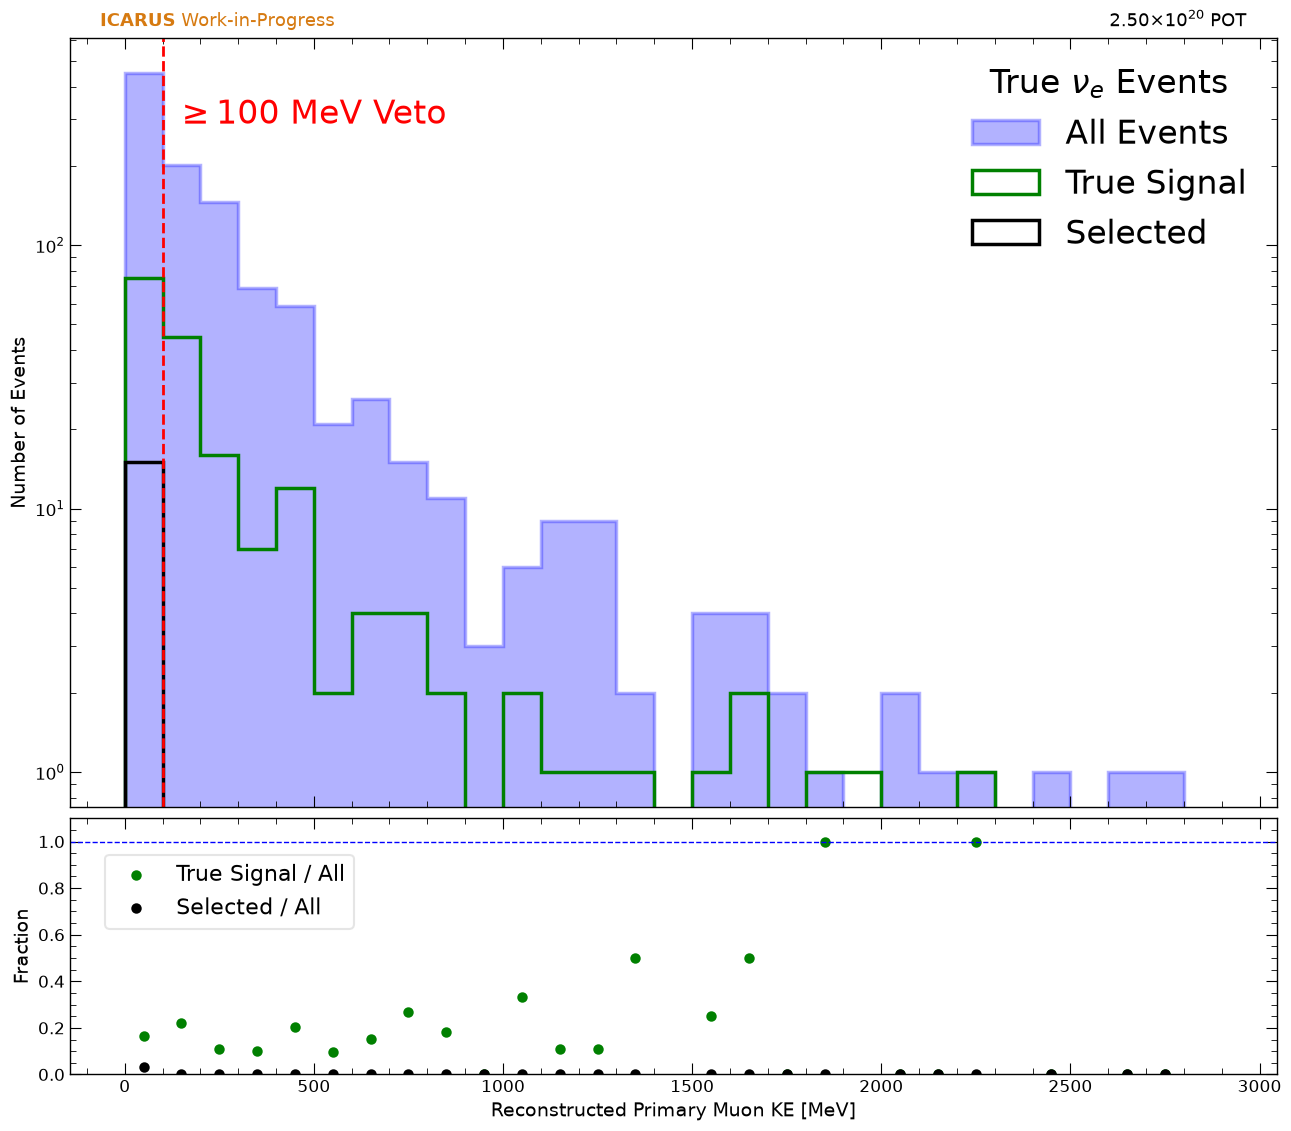

In [32]:
bins = np.arange(0, 3000, 100)

all_hist,      _ = np.histogram(all_muKE[((all_cat==0) | (all_cat==1)) & (all_primary > 0.5)], bins=bins)
signal_hist,   _ = np.histogram(signal_muKE[(signal_cat==0) & (signal_primary > 0.5)], bins=bins)
selected_hist, _ = np.histogram(selected_muKE[(selected_cat==0) & (selected_primary > 0.5)], bins=bins)

with np.errstate(divide='ignore', invalid='ignore'):
    signal_ratio   = np.where(all_hist > 0, signal_hist   / all_hist, np.nan)
    selected_ratio = np.where(all_hist > 0, selected_hist / all_hist, np.nan)

bin_centers = 0.5 * (np.array(bins[:-1]) + np.array(bins[1:]))

fig, (ax, ax_ratio) = plt.subplots(2, 1, figsize=(12.8, 11.2),
                                    gridspec_kw={'height_ratios': [3, 1]},
                                    sharex=True)
fig.subplots_adjust(hspace=0.05)

ax.hist(all_muKE[((all_cat==0) | (all_cat==1)) & (all_primary > 0.5)],           bins=bins, histtype='stepfilled', label='All Events',      color='blue',  alpha=0.3, edgecolor='blue',  linewidth=2.5)
ax.hist(signal_muKE[(signal_cat==0) & (signal_primary > 0.5)],     bins=bins, histtype='step',       label='True Signal',     color='black', edgecolor='green', linewidth=2.5)
ax.hist(selected_muKE[(selected_cat==0) & (selected_primary > 0.5)], bins=bins, histtype='step',       label='Selected', color='red',   edgecolor='black',   linewidth=2.5)
ax.legend(title=r'True $\nu_e$ Events', fontsize=24, title_fontsize=24, loc='best')
ax.set_yscale('log')
ax.set_ylabel('Number of Events')

ax.axvline(100, color='red', linestyle='--', linewidth=2)
ax.text(0.2, 0.9, r'$\geq100$ MeV Veto', transform=ax.transAxes, fontsize=24, ha='center', va='center', color='red')
stamp(ax, pot=2.5e20, work_in_progress=True)

ratio_bins = [bins[i] + (bins[i+1] - bins[i]) / 2 for i in range(len(bins) - 1)]
print(ratio_bins)

ax_ratio.scatter(ratio_bins, signal_ratio, color='green', label='True Signal / All')
ax_ratio.scatter(ratio_bins, selected_ratio, color='black', label='Selected / All')
ax_ratio.axhline(1, color='blue', linestyle='--', linewidth=1)
ax_ratio.set_ylabel('Fraction')
ax_ratio.set_xlabel(r'Reconstructed Primary Muon KE [MeV]')
ax_ratio.set_ylim(0, 1.1)
ax_ratio.legend(fontsize=16, loc='upper left', framealpha=0.5, facecolor='white', frameon=True, bbox_to_anchor=(0.02, 0.9))

plt.show()